In [32]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [33]:
import numpy as np
from mytools.data import vitems
from crafts_stack.utils import read_h5_data_with_mask
from mytools.estimate_fixwidth import get_signal_level_fixwidth_multi, get_averaged_signal_levels
from crafts_stack.measure import Measurement

from mytools.plot import (
make_figure, 
plot_heatmap,  
plot_axlines, 
save_plot,
plt,
)
from mytools.plot_custom import plot_profile_fixwidth_2r

# CRAFTS

In [34]:
path = "../../data/crafts_df122k_xsize3000_nfs10_mean_numerical_result.h5"
vitems(path)

Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10
Type: Group
Attributes (0):
 None
Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10/fit_mask
Type: Dataset
Shape: (120, 120)
Dtype: bool
Attributes (0):
 None
Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10/fitted
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10/jk_mean_residual
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10/jk_std
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10/peak_mask
Type: Dataset
Shape: (120, 120)
Dtype: bool
Attributes (0):
 None
Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10/residual
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10/stack
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_rmfg10_xsize3000_nfs10
Type:

## read PCA results

In [35]:
temp = 'crafts_df122k_rmfg%s_xsize3000_nfs10'
unit = r'$T\ [\mu$K]'

modes = [
    1,5,10,15,20,
    25,30,35,40,45
]
grp_keys = [temp%mode for mode in modes]
grp_keys

['crafts_df122k_rmfg1_xsize3000_nfs10',
 'crafts_df122k_rmfg5_xsize3000_nfs10',
 'crafts_df122k_rmfg10_xsize3000_nfs10',
 'crafts_df122k_rmfg15_xsize3000_nfs10',
 'crafts_df122k_rmfg20_xsize3000_nfs10',
 'crafts_df122k_rmfg25_xsize3000_nfs10',
 'crafts_df122k_rmfg30_xsize3000_nfs10',
 'crafts_df122k_rmfg35_xsize3000_nfs10',
 'crafts_df122k_rmfg40_xsize3000_nfs10',
 'crafts_df122k_rmfg45_xsize3000_nfs10']

In [36]:
result = read_h5_data_with_mask(path, grp_keys)

In [37]:
result.keys()

dict_keys(['crafts_df122k_rmfg1_xsize3000_nfs10', 'crafts_df122k_rmfg5_xsize3000_nfs10', 'crafts_df122k_rmfg10_xsize3000_nfs10', 'crafts_df122k_rmfg15_xsize3000_nfs10', 'crafts_df122k_rmfg20_xsize3000_nfs10', 'crafts_df122k_rmfg25_xsize3000_nfs10', 'crafts_df122k_rmfg30_xsize3000_nfs10', 'crafts_df122k_rmfg35_xsize3000_nfs10', 'crafts_df122k_rmfg40_xsize3000_nfs10', 'crafts_df122k_rmfg45_xsize3000_nfs10'])

## show PCA results

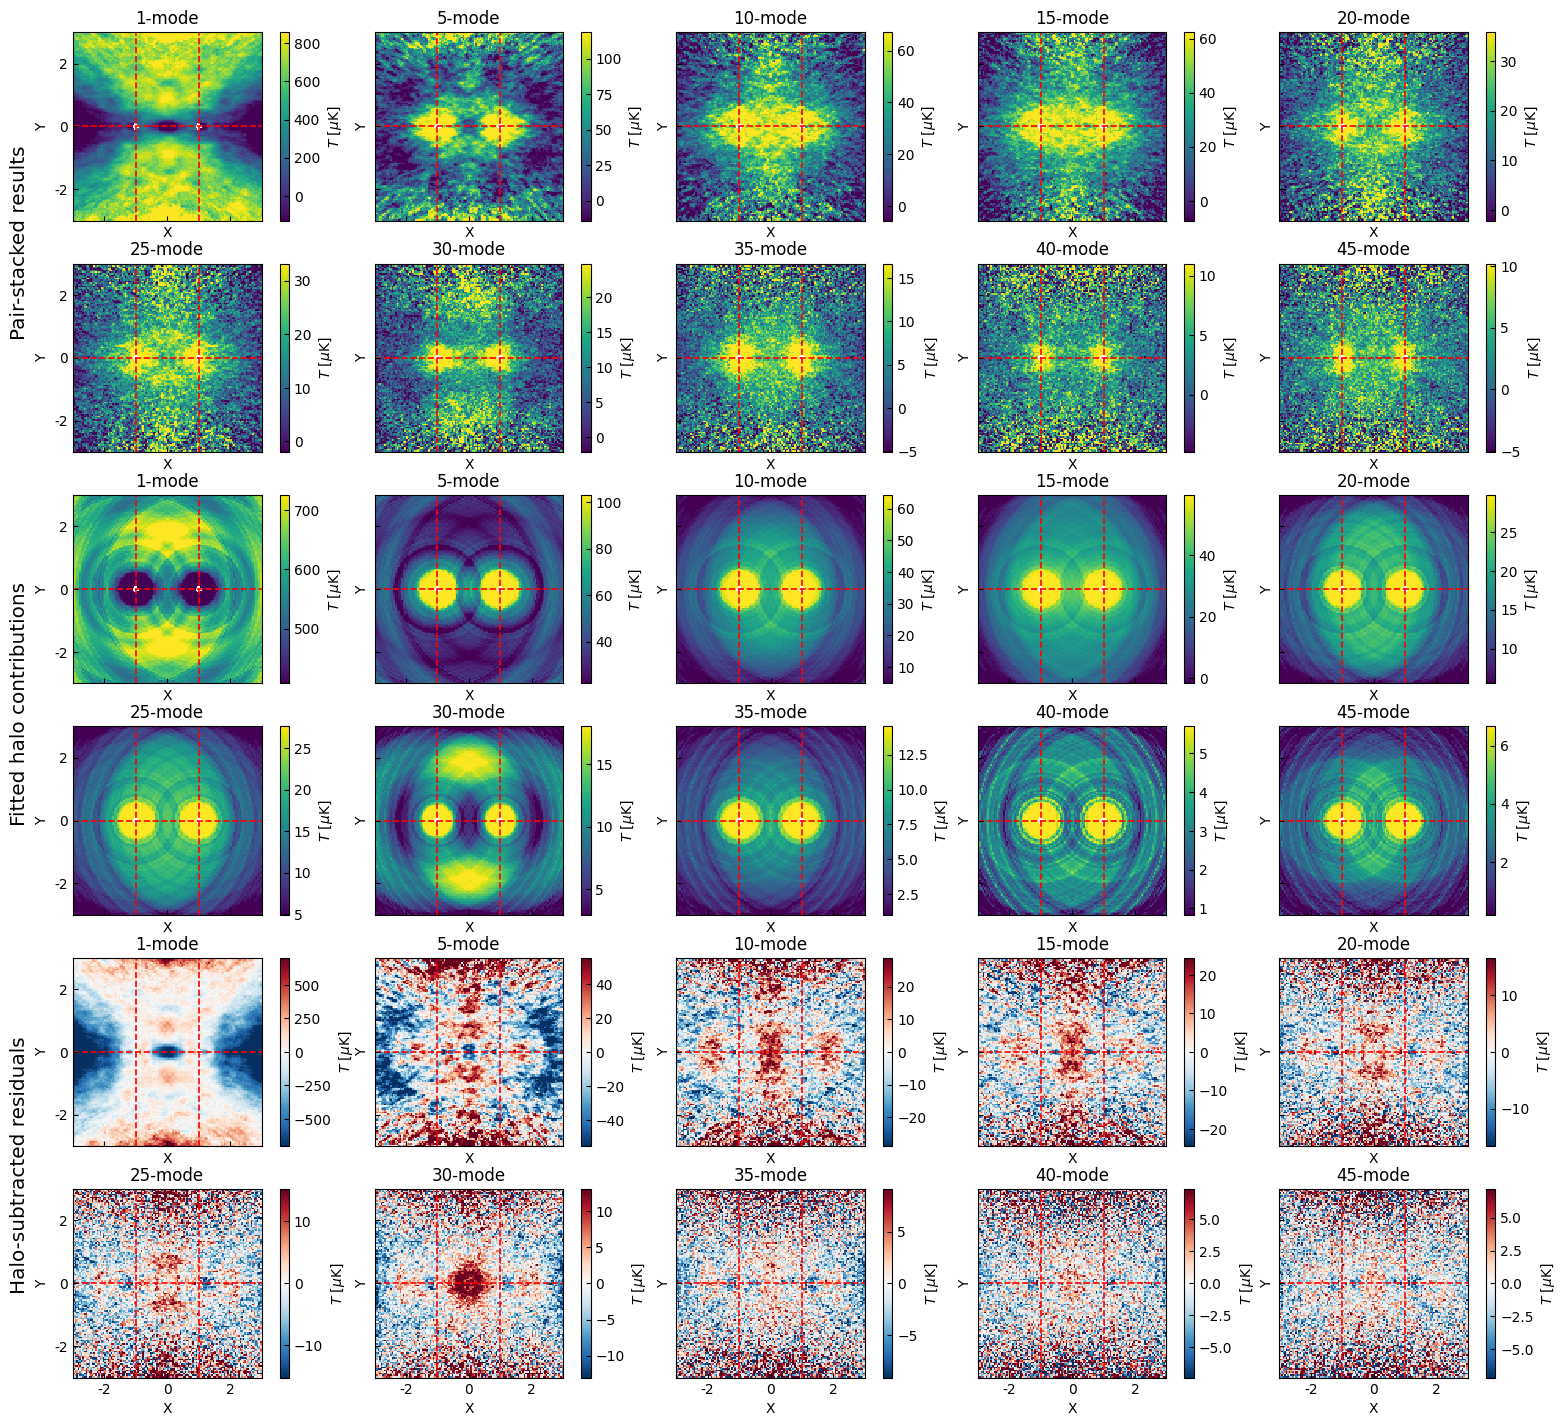

In [7]:
fig, axes = make_figure(6, 5, (18, 18), wspace=0.6, hspace=0.01)
# fig.suptitle('CRAFTS_df122k_PCA_rmfg_xsize3000_nfs10_mean', y=0.95)

fig.text(x=0.09, y=0.7, s='Pair-stacked results', fontsize='x-large', rotation='vertical')
for mode, ax in zip(modes, axes.flatten()[:10]):
    key = temp%mode
    dset = result[key]['stack']
    plot_heatmap(dset, ax=ax, cbar_label=unit, title='%s-mode'%mode)
    plot_axlines(ax=ax, vl=[40, 80], hl=60, linewidth=1.2)

fig.text(x=0.09, y=0.43, s='Fitted halo contributions', fontsize='x-large', rotation='vertical')
for mode, ax in zip(modes, axes.flatten()[10:20]):
    key = temp%mode
    dset = result[key]['fitted']
    plot_heatmap(dset, ax=ax, cbar_label=unit, title='%s-mode'%mode)
    plot_axlines(ax=ax, vl=[40, 80], hl=60, linewidth=1.2)
    
fig.text(x=0.09, y=0.17, s='Halo-subtracted residuals', fontsize='x-large', rotation='vertical')
for mode, ax in zip(modes, axes.flatten()[20:]):
    key = temp%mode
    dset = result[key]['residual']
    plot_heatmap(dset, ax=ax, cbar_label=unit, title='%s-mode'%mode, sym_cbar=True, cmap='RdBu_r')
    plot_axlines(ax=ax, vl=[40, 80], hl=60, linewidth=1.2)
    
# fig.text(x=0.09, y=0.18, s='Normalized residuals', fontsize='x-large', rotation='vertical')
# for mode, ax in zip(modes, axes.flatten()[20:]):
#     key = temp%mode
#     dset = result[key]['residual'] / result[key]['jk_std']
#     plot_heatmap(dset, ax=ax, cbar_label=r'$T/\sigma$', title='%s-mode'%mode, vmax=3, vmin=-3, cmap='RdBu_r')
#     plot_axlines(ax=ax, vl=[40, 80], hl=60)
    
figname = 'img_crafts_df122k_pca_rmfg_xsize3000_nfs10_mean_numerical_stack_fit_res.png'
# save_plot(fig, figname)

## estimate signal

In [38]:
width = 0.3
d_list = [result[temp%mode]['residual'] for mode in modes]
derr_list = [result[temp%mode]['jk_std'] for mode in modes]

lx_list, ly_list, lyerr_list, clrb_list, clrb_list = get_signal_level_fixwidth_multi(d_list, width, derr_list)

In [39]:
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec

Plot saved to img_crafts_df122k_pca_rmfg_xsize3000_nfs10_mean_numerical_res_profiles.png


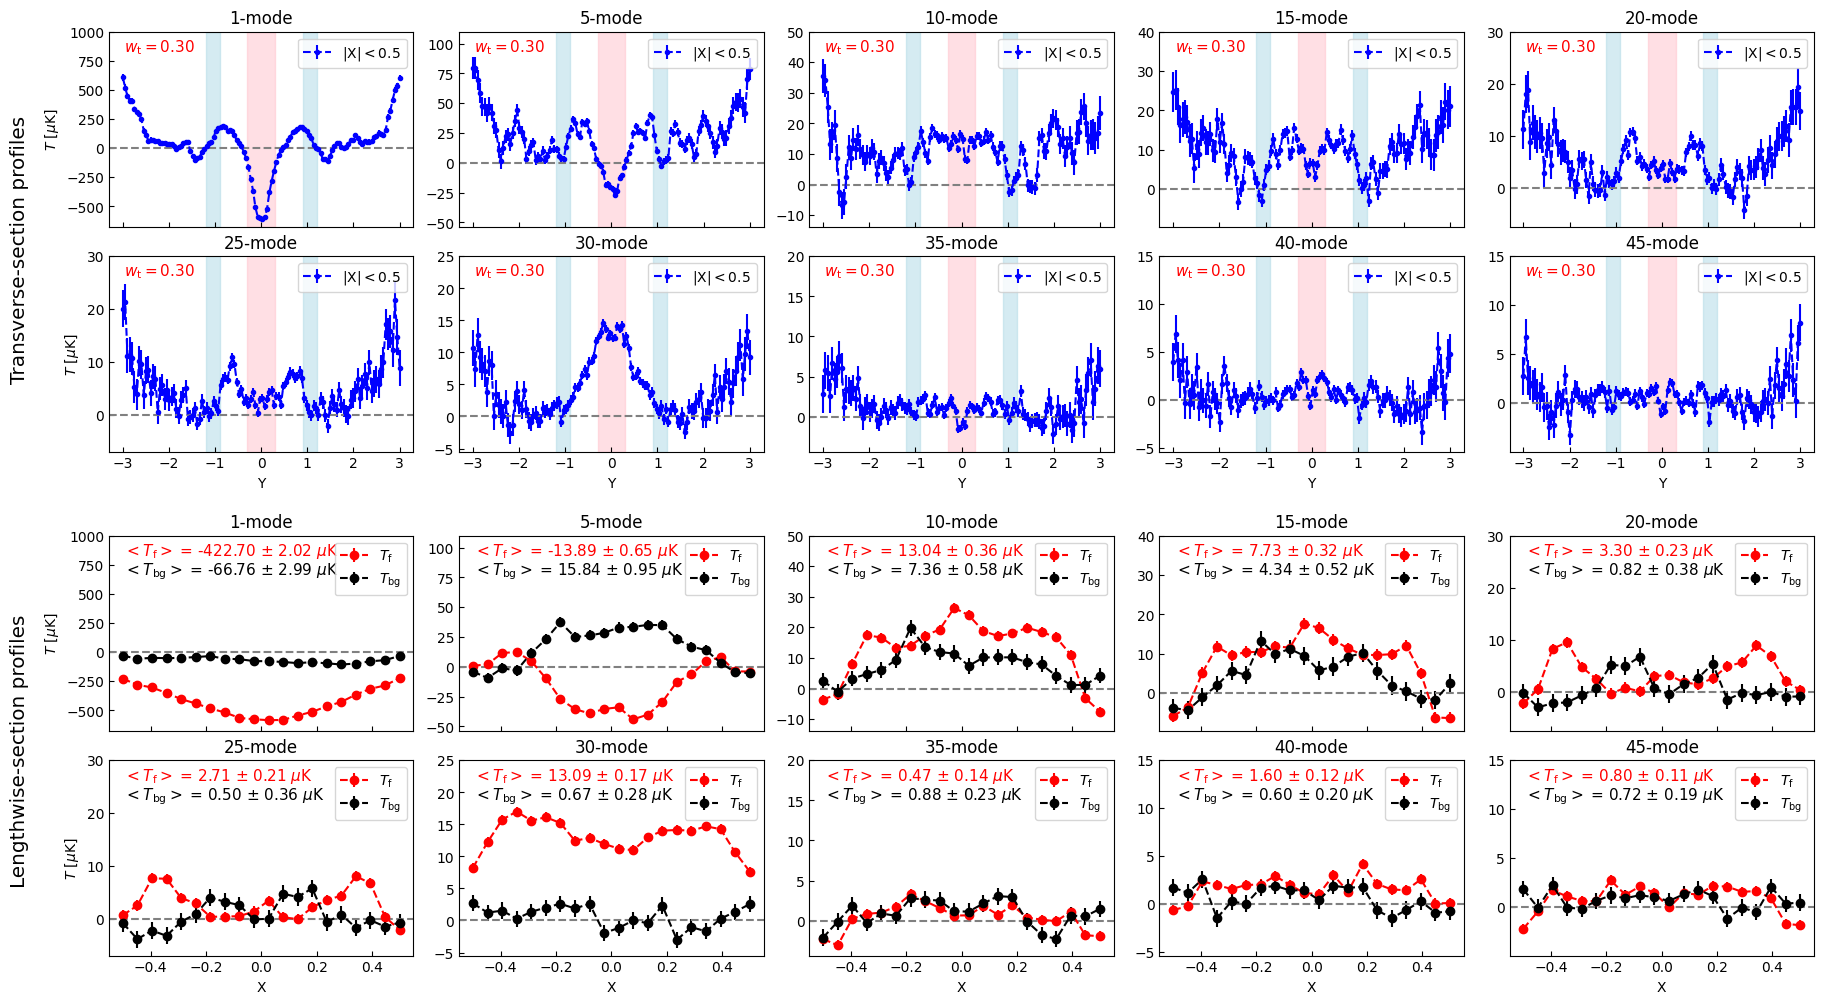

In [40]:
nrows=2
ncols=5

fig = plt.figure(figsize=(22, 12))

gs_main = GridSpec(2, 1, figure=fig, height_ratios=[1, 1], hspace=0.2)

gs_top = GridSpecFromSubplotSpec(nrows, ncols, subplot_spec=gs_main[0],
                                 wspace=0.15, hspace=0.15)

gs_bot = GridSpecFromSubplotSpec(nrows, ncols, subplot_spec=gs_main[1],
                                 wspace=0.15, hspace=0.15)

axes = np.empty((nrows, ncols*2), dtype=object)

title_list = ['%s-mode'%mode for mode in modes]
for i in range(2):
    for j in range(10):
        if i==0 :
            axes[i, j] = fig.add_subplot(gs_top[j//5, j%5])
        else:
            axes[i, j] = fig.add_subplot(gs_bot[j//5, j%5], sharey=axes[0, j])
        if j < 5:
            axes[i, j].set_xticklabels([]) # 隐藏刻度标签
        elif i:
            axes[i, j].set_xlabel('X')
        else:
            axes[i, j].set_xlabel('Y')

        if j%5:
            axes[i, j].set_ylabel('') # 隐藏刻度标签
        else:
            axes[i, j].set_ylabel(r'$T\ [\mu$K]')

        axes[i,j].set_title(title_list[j])

plot_profile_fixwidth_2r(
    lx_list, 
    ly_list,
    width=width,
    axes=axes,
    y_err=lyerr_list,
    xlabel=None,
    ylabel=None,
    title=None,
    fontsize=11,
);

axes[0,0].set_ylim(ymax=1000)
axes[0,1].set_ylim(ymax=110)
axes[0,2].set_ylim(ymax=50)
axes[0,3].set_ylim(ymax=40)
axes[0,4].set_ylim(ymax=30)
axes[0,5].set_ylim(ymax=30)
axes[0,6].set_ylim(ymax=25)
axes[0,7].set_ylim(ymax=20)
axes[0,8].set_ylim(ymax=15)
axes[0,9].set_ylim(ymax=15)

s1, s2 ='Transverse-section profiles', 'Lengthwise-section profiles' #'Y-profiles', 'X-profiles'
fig.text(x=0.08, y=0.59, s=s1, fontsize='x-large', rotation='vertical')
fig.text(x=0.08, y=0.17, s=s2, fontsize='x-large', rotation='vertical')

figname = 'img_crafts_df122k_pca_rmfg_xsize3000_nfs10_mean_numerical_res_profiles.png'
save_plot(fig, figname)

## show trend

In [11]:
tf_list, tf_err_list, tbg_list, tbg_err_list = get_averaged_signal_levels(ly_list[1:], lyerr_list[1:])

In [12]:
m_tf = Measurement(tf_list, tf_err_list)
m_tbg = Measurement(tbg_list, tbg_err_list)

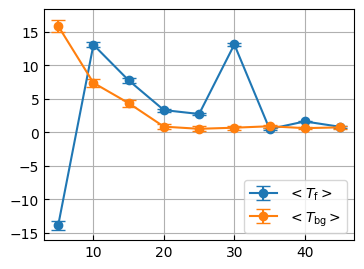

In [13]:
fig, ax = make_figure(1,1,figsize=(4,3), aspect=None)
m_tf.plot(ax=ax, x=modes[1:], label=r'$<T_{\rm f}>$')
m_tbg.plot(ax=ax, x=modes[1:], label=r'$<T_{\rm bg}>$')

# TNG

## read PCA loss results

In [14]:
tng_path = "../../data/tng_df120k_pcaloss_xsize3000_nfs10_mean_numerical_result.h5"
vitems(tng_path)

Item: tng_df120k_rmfg0_pcaloss_xsize3000_nfs10
Type: Group
Attributes (0):
 None
Item: tng_df120k_rmfg0_pcaloss_xsize3000_nfs10/fit_mask
Type: Dataset
Shape: (120, 120)
Dtype: bool
Attributes (0):
 None
Item: tng_df120k_rmfg0_pcaloss_xsize3000_nfs10/fitted
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: tng_df120k_rmfg0_pcaloss_xsize3000_nfs10/jk_mean_residual
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: tng_df120k_rmfg0_pcaloss_xsize3000_nfs10/jk_std
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: tng_df120k_rmfg0_pcaloss_xsize3000_nfs10/peak_mask
Type: Dataset
Shape: (120, 120)
Dtype: bool
Attributes (0):
 None
Item: tng_df120k_rmfg0_pcaloss_xsize3000_nfs10/residual
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: tng_df120k_rmfg0_pcaloss_xsize3000_nfs10/stack
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: tng_df120k_rmfg10_pcaloss_xsize3000_nfs10


In [15]:
tng_temp = 'tng_df120k_rmfg%s_pcaloss_xsize3000_nfs10'
unit = r'$T\ [\mu$K]'

tng_modes = [
    0,5,10,15,20,
    25,30,35,40,45
]
tng_grp_keys = [tng_temp%mode for mode in tng_modes]
tng_grp_keys

['tng_df120k_rmfg0_pcaloss_xsize3000_nfs10',
 'tng_df120k_rmfg5_pcaloss_xsize3000_nfs10',
 'tng_df120k_rmfg10_pcaloss_xsize3000_nfs10',
 'tng_df120k_rmfg15_pcaloss_xsize3000_nfs10',
 'tng_df120k_rmfg20_pcaloss_xsize3000_nfs10',
 'tng_df120k_rmfg25_pcaloss_xsize3000_nfs10',
 'tng_df120k_rmfg30_pcaloss_xsize3000_nfs10',
 'tng_df120k_rmfg35_pcaloss_xsize3000_nfs10',
 'tng_df120k_rmfg40_pcaloss_xsize3000_nfs10',
 'tng_df120k_rmfg45_pcaloss_xsize3000_nfs10']

In [16]:
tng_result = read_h5_data_with_mask(tng_path, tng_grp_keys)

## show PCA loss results

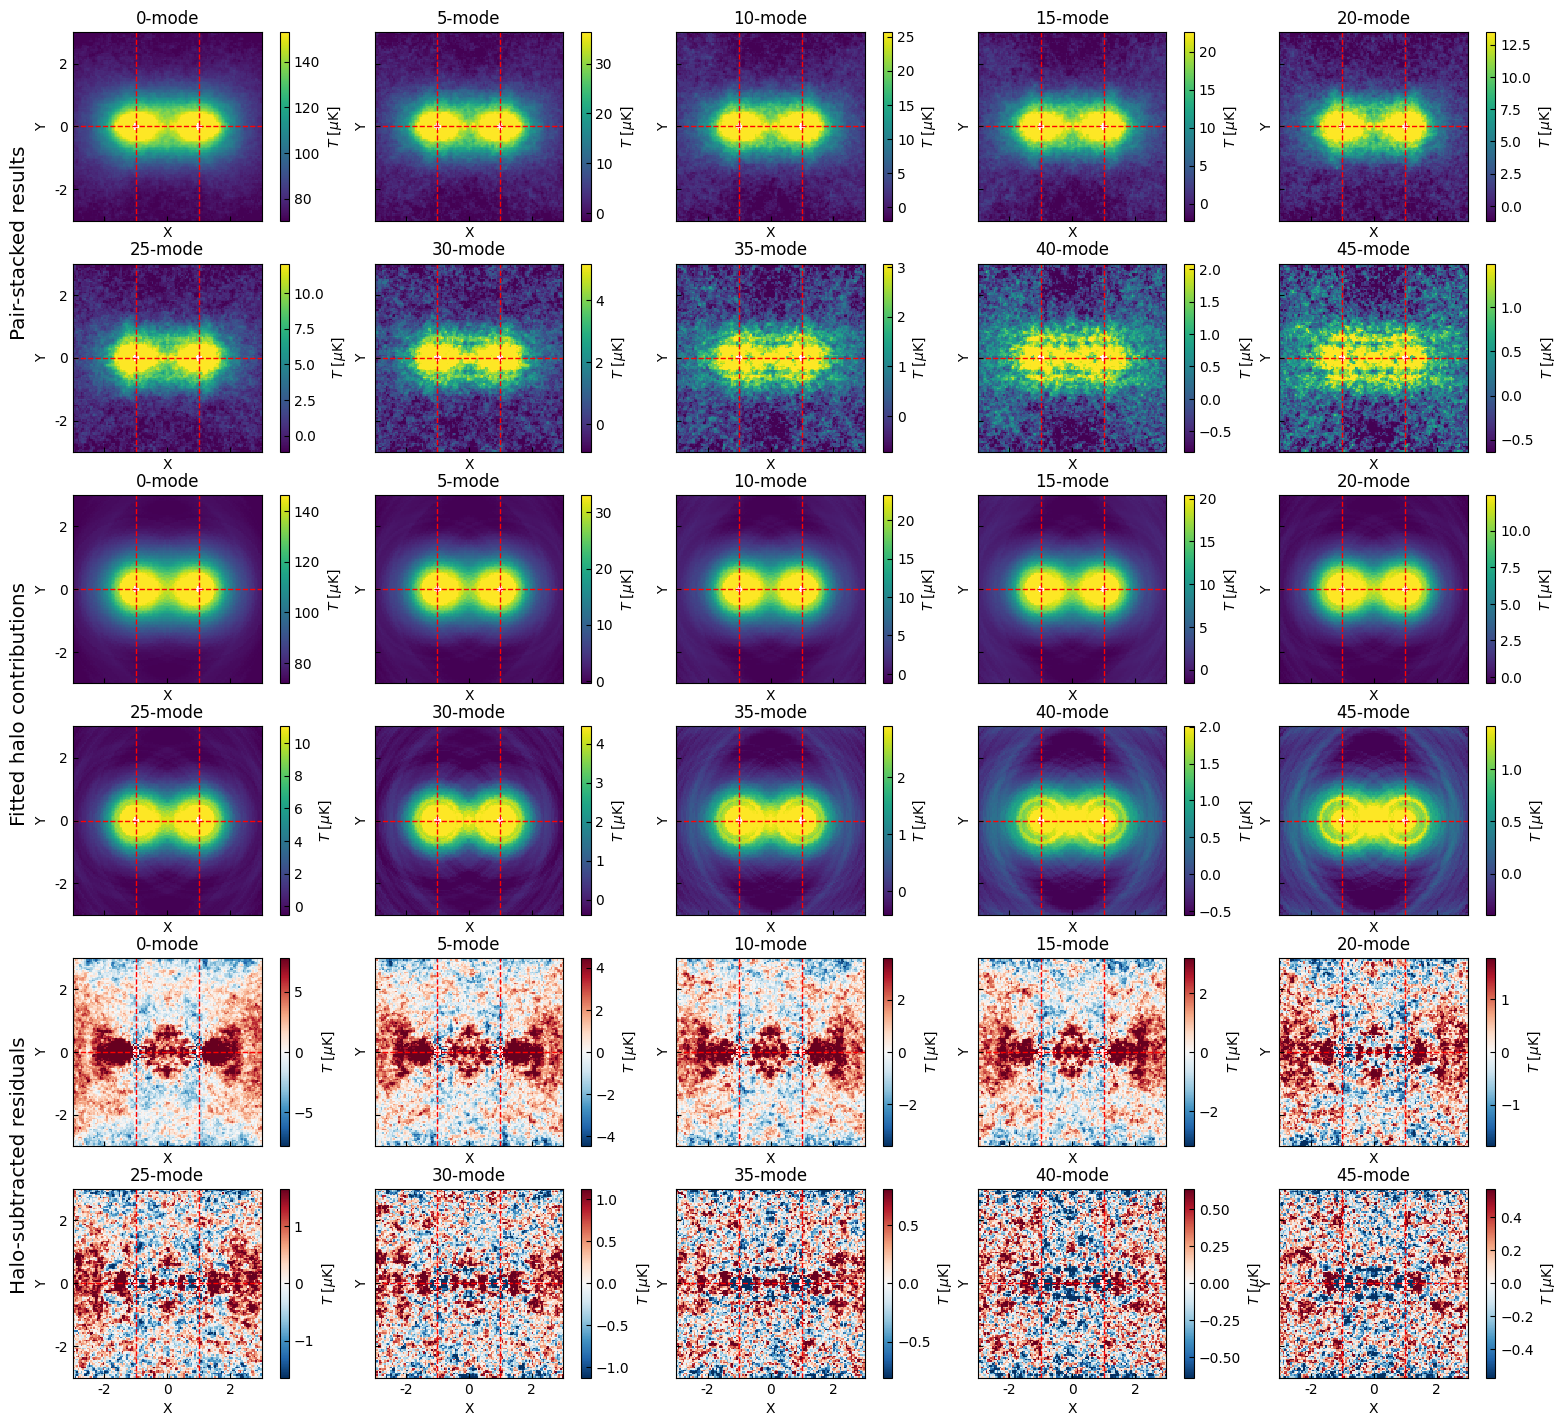

In [17]:
fig, axes = make_figure(6, 5, (18, 18), wspace=0.6, hspace=0.01)

fig.text(x=0.09, y=0.7, s='Pair-stacked results', fontsize='x-large', rotation='vertical')
for mode, ax in zip(tng_modes, axes.flatten()[:10]):
    key = tng_temp%mode
    dset = tng_result[key]['stack']
    plot_heatmap(dset, ax=ax, cbar_label=unit, title='%s-mode'%mode)
    plot_axlines(ax=ax, vl=[40, 80], hl=60)

fig.text(x=0.09, y=0.43, s='Fitted halo contributions', fontsize='x-large', rotation='vertical')
for mode, ax in zip(tng_modes, axes.flatten()[10:20]):
    key = tng_temp%mode
    dset = tng_result[key]['fitted']
    plot_heatmap(dset, ax=ax, cbar_label=unit, title='%s-mode'%mode)
    plot_axlines(ax=ax, vl=[40, 80], hl=60)
    
fig.text(x=0.09, y=0.17, s='Halo-subtracted residuals', fontsize='x-large', rotation='vertical')
for mode, ax in zip(tng_modes, axes.flatten()[20:]):
    key = tng_temp%mode
    dset = tng_result[key]['residual']
    plot_heatmap(dset, ax=ax, cbar_label=unit, title='%s-mode'%mode, sym_cbar=True, cmap='RdBu_r')
    plot_axlines(ax=ax, vl=[40, 80], hl=60)

# fig.text(x=0.09, y=0.18, s='Normalized residuals', fontsize='x-large', rotation='vertical')
# for mode, ax in zip(tng_modes, axes.flatten()[20:]):
#     key = tng_temp%mode
#     dset = tng_result[key]['residual'] / tng_result[key]['jk_std']
#     plot_heatmap(dset, ax=ax, cbar_label=r'$T/\sigma$', title='%s-mode'%mode, vmax=3, vmin=-3, cmap='RdBu_r')
#     plot_axlines(ax=ax, vl=[40, 80], hl=60)
    
figname = 'img_tng_df120k_pca_rmfg_loss_xsize3000_nfs10_mean_numerical_stack_fit_res.png'
# save_plot(fig, figname)

## Estimate signal

In [18]:
tng_d_list = [tng_result[tng_temp%mode]['residual'] for mode in tng_modes]
tng_derr_list = [tng_result[tng_temp%mode]['jk_std'] for mode in tng_modes]

tng_lx_list, tng_ly_list, tng_lyerr_list, tng_clrb_list, tng_clrb_list = get_signal_level_fixwidth_multi(tng_d_list, width, tng_derr_list)

Plot saved to img_tng_df120k_pca_rmfg_loss_xsize3000_nfs10_mean_numerical_res_profiles.png


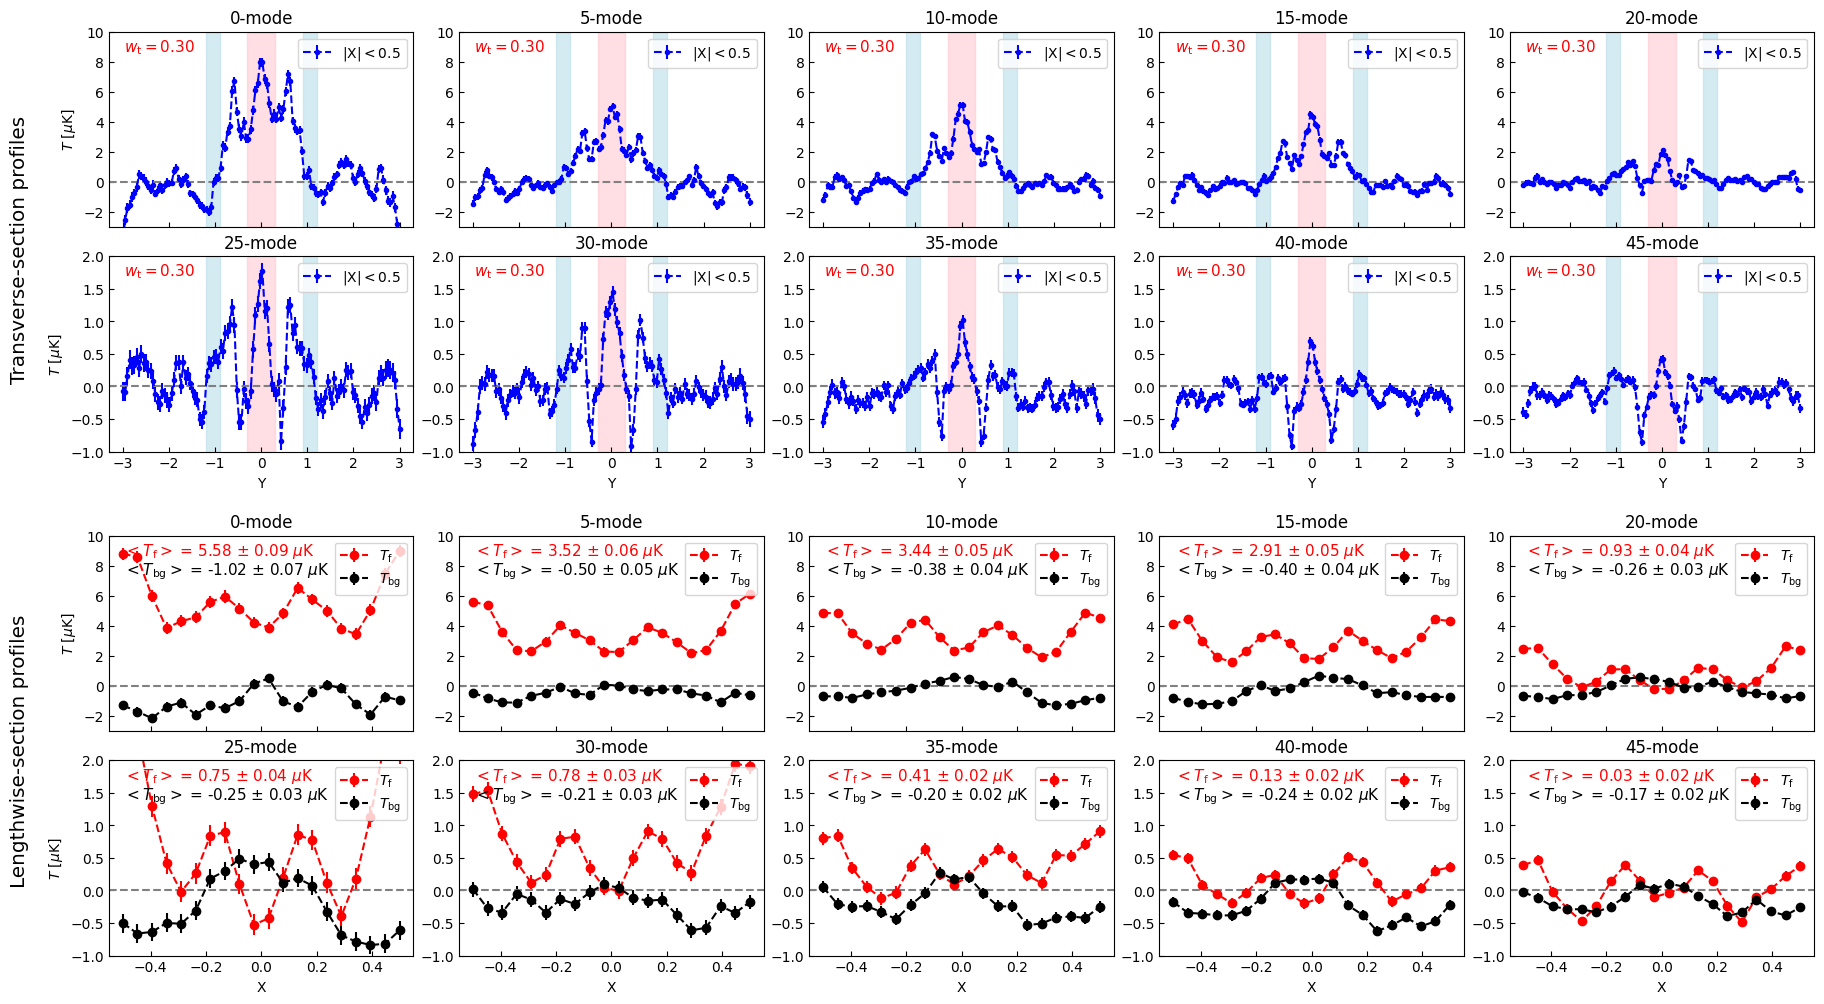

In [19]:
nrows=2
ncols=5

fig = plt.figure(figsize=(22, 12))

gs_main = GridSpec(2, 1, figure=fig, height_ratios=[1, 1], hspace=0.2)

gs_top = GridSpecFromSubplotSpec(nrows, ncols, subplot_spec=gs_main[0],
                                 wspace=0.15, hspace=0.15)

gs_bot = GridSpecFromSubplotSpec(nrows, ncols, subplot_spec=gs_main[1],
                                 wspace=0.15, hspace=0.15)

axes = np.empty((nrows, ncols*2), dtype=object)

title_list = ['%s-mode'%mode for mode in tng_modes]
for i in range(2):
    for j in range(10):
        if i==0 :
            axes[i, j] = fig.add_subplot(gs_top[j//5, j%5])
        else:
            axes[i, j] = fig.add_subplot(gs_bot[j//5, j%5], sharey=axes[0, j])
        if j < 5:
            axes[i, j].set_xticklabels([]) # 隐藏刻度标签
        elif i:
            axes[i, j].set_xlabel('X')
        else:
            axes[i, j].set_xlabel('Y')

        if j%5:
            axes[i, j].set_ylabel('') # 隐藏刻度标签
        else:
            axes[i, j].set_ylabel(r'$T\ [\mu$K]')

        axes[i,j].set_title(title_list[j])

plot_profile_fixwidth_2r(
    tng_lx_list, 
    tng_ly_list,
    width=width,
    axes=axes,
    y_err=tng_lyerr_list,
    xlabel=None,
    ylabel=None,
    title=None,
    fontsize=11,
);

axes[0,0].set_ylim(ymax=10,ymin=-3)
axes[0,1].set_ylim(ymax=10,ymin=-3)
axes[0,2].set_ylim(ymax=10,ymin=-3)
axes[0,3].set_ylim(ymax=10,ymin=-3)
axes[0,4].set_ylim(ymax=10,ymin=-3)
axes[0,5].set_ylim(ymax=2,ymin=-1)
axes[0,6].set_ylim(ymax=2,ymin=-1)
axes[0,7].set_ylim(ymax=2,ymin=-1)
axes[0,8].set_ylim(ymax=2,ymin=-1)
axes[0,9].set_ylim(ymax=2,ymin=-1)

s1, s2 ='Transverse-section profiles', 'Lengthwise-section profiles' #'Y-profiles', 'X-profiles'
fig.text(x=0.08, y=0.59, s=s1, fontsize='x-large', rotation='vertical')
fig.text(x=0.08, y=0.17, s=s2, fontsize='x-large', rotation='vertical')

figname = 'img_tng_df120k_pca_rmfg_loss_xsize3000_nfs10_mean_numerical_res_profiles.png'
save_plot(fig, figname)

## show trend

In [20]:
tng_tf_list, tng_tf_err_list, tng_tbg_list, tng_tbg_err_list = get_averaged_signal_levels(tng_ly_list, tng_lyerr_list)

In [21]:
tng_m_tf = Measurement(tng_tf_list, tng_tf_err_list)
tng_m_tbg = Measurement(tng_tbg_list, tng_tbg_err_list)

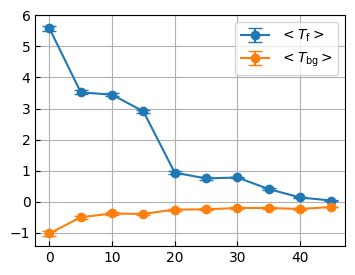

In [22]:
fig, ax = make_figure(1,1,figsize=(4,3), aspect=None)
tng_m_tf.plot(ax=ax, x=tng_modes, label=r'$<T_{\rm f}>$')
tng_m_tbg.plot(ax=ax, x=tng_modes, label=r'$<T_{\rm bg}>$')

## show correction factor and corrected signal level

In [23]:
cf_f = tng_m_tf[0]/ tng_m_tf 
cf_bg = tng_m_tbg[0]/ tng_m_tbg

m_tf_corrected = m_tf * cf_f[1:]
m_tbg_corrected = m_tbg * cf_bg[1:]

Plot saved to img_tng_pca_loss_numerical_signal_levels.png


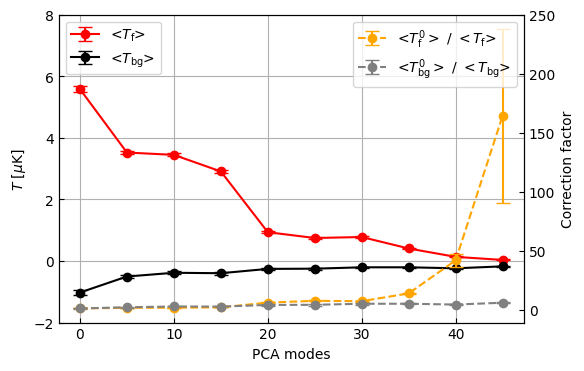

In [24]:
fig, ax = make_figure(1,1, figsize=(6,4), aspect=None, sharey=False)

tng_m_tf.plot(ax=ax, x=tng_modes, label=r'<$T_{\rm f}$>', c='r',)
tng_m_tbg.plot(ax=ax, x=tng_modes, label=r'<$T_{\rm bg}$>', c='k',)

ax2 = ax.twinx()
cf_f.plot(ax=ax2, x=tng_modes, label=r'<$T_{\rm f}^0> \ /\ <T_{\rm f}$>',fmt='--o', c='orange', grid=False)
cf_bg.plot(ax=ax2, x=tng_modes, label=r'<$T_{\rm bg}^0>\ /\ <T_{\rm bg}$>',fmt='--o', c='gray', grid=False)

ax.set_xlabel('PCA modes')
ax.set_ylabel(r'$T\ [\mu$K]')
ax.set_ylim(-2, 8)
ax.legend(loc='upper left')
ax2.set_ylabel('Correction factor')
# ax2.set_ylim(0, 20)
ax2.legend(loc='upper right')
# ax2.set_title('Mock CRAFTS')

fname = 'img_tng_pca_loss_numerical_signal_levels.png'
save_plot(fig, fname)

Plot saved to img_crafts_pca_numerical_signal_levels.png


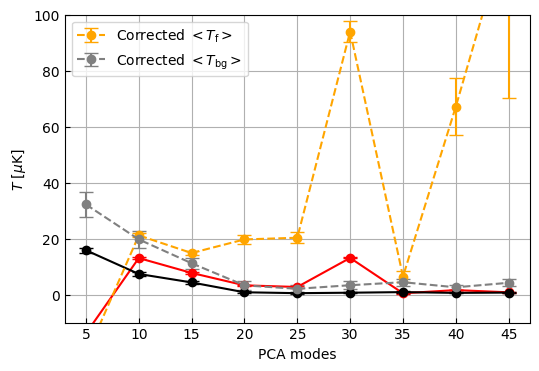

In [25]:
fig, ax = make_figure(1,1, figsize=(6,4), aspect=None, sharey=False)

m_tf.plot(ax=ax, x=modes[1:], c='r')
m_tbg.plot(ax=ax, x=modes[1:], c='k')
m_tf_corrected.plot(ax=ax, x=modes[1:], label=r'Corrected $<T_{\rm f}>$', c='orange' ,fmt='--o')
m_tbg_corrected.plot(ax=ax, x=modes[1:], label=r'Corrected $<T_{\rm bg}>$',  c='gray' ,fmt='--o')

ax.set_ylabel(r'$T\ [\mu$K]')
ax.set_ylim(-10, 100)
ax.legend(loc='upper left')
ax.set_xlabel('PCA modes')
# ax.set_title('CRAFTS')

fname = 'img_crafts_pca_numerical_signal_levels.png'
save_plot(fig, fname)

Text(0.5, 1.0, 'Mock')

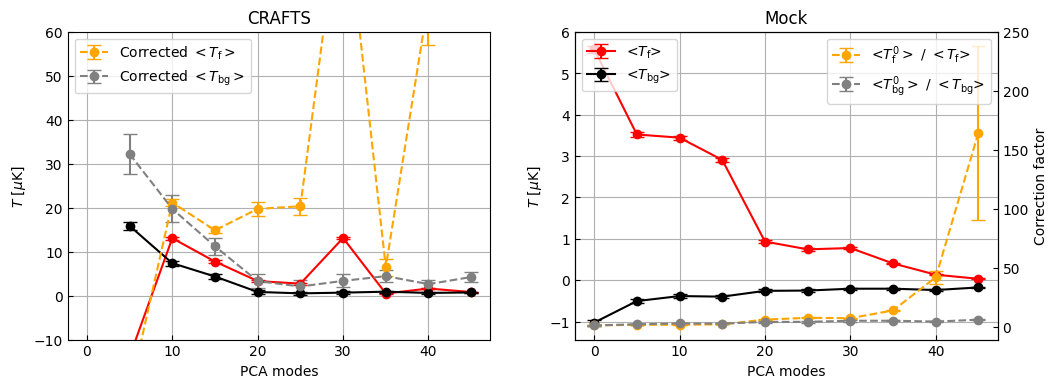

In [26]:
fig, (ax, ax2) = make_figure(1,2, figsize=(12,4), wspace=0.2, aspect=None, sharey=False)

# left panel
# m_tf[1:].plot(ax=ax, x=modes[1:], label=r'$<T_{\rm f}>$', c='r')
# m_tbg[1:].plot(ax=ax, x=modes[1:], label=r'$<T_{\rm bg}>$', c='k')
m_tf.plot(ax=ax, x=modes[1:], c='r')
m_tbg.plot(ax=ax, x=modes[1:], c='k')
ax.set_ylabel(r'$T\ [\mu$K]')
ax.set_ylim(-10, 60)


# _ax = ax.twinx()
_ax=ax
m_tf_corrected.plot(ax=_ax, x=modes[1:], label=r'Corrected $<T_{\rm f}>$', c='orange' , fmt='--o')
m_tbg_corrected.plot(ax=_ax, x=modes[1:], label=r'Corrected $<T_{\rm bg}>$',  c='gray' ,fmt='--o')
# _ax.set_ylabel('Correction factor')
# _ax.set_ylim(0, 35)
# _ax.legend(loc='upper right')
ax.legend(loc='upper left')
ax.set_xlabel('PCA modes')
ax.set_title('CRAFTS')

# right panel 
tng_m_tf.plot(ax=ax2, x=tng_modes, label=r'<$T_{\rm f}$>', c='r',)
tng_m_tbg.plot(ax=ax2, x=tng_modes, label=r'<$T_{\rm bg}$>', c='k',)

_ax2 = ax2.twinx()
cf_f.plot(ax=_ax2, x=tng_modes, label=r'<$T_{\rm f}^0> \ /\ <T_{\rm f}$>',fmt='--o', c='orange', grid=False)
cf_bg.plot(ax=_ax2, x=tng_modes, label=r'<$T_{\rm bg}^0>\ /\ <T_{\rm bg}$>',fmt='--o', c='gray', grid=False)

ax2.set_ylabel(r'$T\ [\mu$K]')
# ax2.set_ylim(-2, 10)
ax2.legend(loc='upper left')
_ax2.set_ylabel('Correction factor')
# _ax2.set_ylim(-40, 120)
_ax2.legend(loc='upper right')

ax2.set_xlabel('PCA modes')
ax2.set_title('Mock')

In [27]:
fname = 'img_crafts_pca_numerical_signal_levels.png'
# save_plot(fig, fname)

Text(0, 0.5, 'Correction factor')

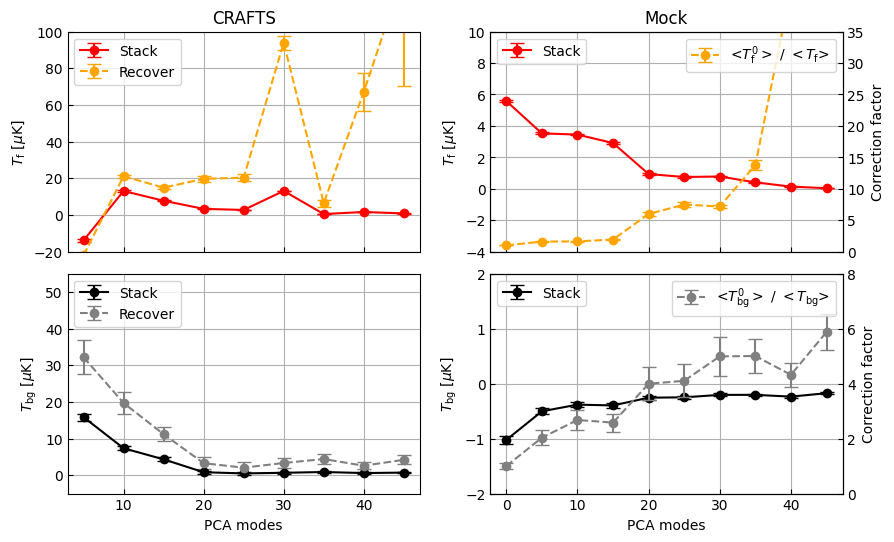

In [28]:
fig, ((ax, ax2), (ax3, ax4)) = make_figure(2,2, figsize=(10,6), wspace=0.2, hspace=0.1, aspect=None, sharey=False, sharex=False)

# left panel
m_tf.plot(ax=ax, x=modes[1:], c='r',label='Stack')
m_tbg.plot(ax=ax3, x=modes[1:], c='k',label='Stack')
# m_tf[1:].plot(ax=ax, x=modes[1:], c='r', label=r'<$T_{\rm f}$>', )
# m_tbg[1:].plot(ax=ax3, x=modes[1:], c='k',label=r'<$T_{\rm bg}$>', )
ax.set_ylabel(r'$T_{\rm f}\ [\mu$K]')
ax.set_ylim(-20, 100)

m_tf_corrected.plot(ax=ax, x=modes[1:], label=r'Recover', c='orange' ,fmt='--o')
m_tbg_corrected.plot(ax=ax3, x=modes[1:], label=r'Recover',  c='gray' ,fmt='--o')
ax.legend(loc='upper left')
ax.set_xticklabels([]) 
ax.set_title('CRAFTS')

# right panel 
tng_m_tf.plot(ax=ax2, x=tng_modes, label='Stack', c='r',)
tng_m_tbg.plot(ax=ax4, x=tng_modes, label='Stack', c='k',)

_ax2 = ax2.twinx()
_ax4 = ax4.twinx()
cf_f.plot(ax=_ax2, x=tng_modes, label=r'<$T_{\rm f}^0> \ /\ <T_{\rm f}$>',fmt='--o', c='orange', grid=False)
cf_bg.plot(ax=_ax4, x=tng_modes, label=r'<$T_{\rm bg}^0>\ /\ <T_{\rm bg}$>',fmt='--o', c='gray', grid=False)

ax2.set_ylabel(r'$T_{\rm f}\ [\mu$K]')
ax2.set_ylim(-4, 10)
ax2.legend(loc='upper left')
_ax2.set_ylabel('Correction factor')
_ax2.set_ylim(0, 35)
_ax2.legend(loc='upper right')

ax2.set_xticklabels([]) 
ax2.set_title('Mock')
ax3.legend(loc='upper left')
ax4.legend(loc='upper left')
_ax4.legend(loc='upper right')
ax3.set_ylabel(r'$T_{\rm bg}\ [\mu$K]')
ax4.set_ylabel(r'$T_{\rm bg}\ [\mu$K]')
ax3.set_ylim(-5, 55)
ax4.set_ylim(-2, 2)
_ax4.set_ylim(0, 8)

ax3.set_xlabel('PCA modes')
ax4.set_xlabel('PCA modes')

_ax4.set_ylabel('Correction factor')

In [29]:
fname = 'img_crafts_pca_numerical_signal_levels_null_split.png'
save_plot(fig, fname)

Plot saved to img_crafts_pca_numerical_signal_levels_null_split.png


# use diff

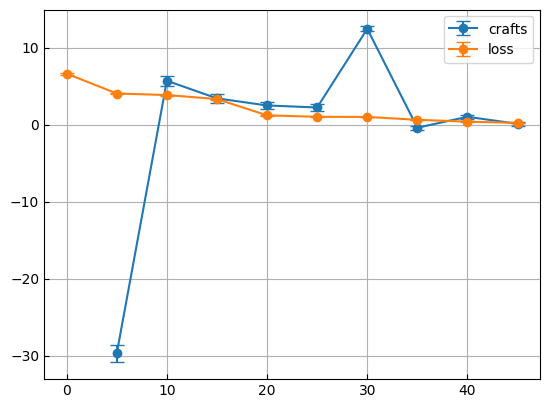

In [30]:
tng_m_diff = tng_m_tf - tng_m_tbg
m_tf_abs = m_tf - m_tbg

m_tf_abs.plot(x=modes[1:], label='crafts')
tng_m_diff.plot(x=tng_modes, label='loss')

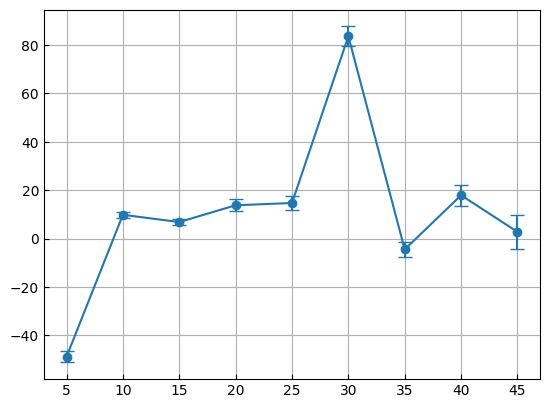

In [31]:
tng_m_diff_cf = tng_m_diff[0] / tng_m_diff

m_tf_correct_test = m_tf_abs * tng_m_diff_cf[1:]
m_tf_correct_test.plot(x=modes[1:])